# 02 - Model results and error analysis

Run `python -m src.train` before this notebook.

1. Compare the baselines and the models.
2. Look at how the threshold was chosen.
3. Feature importance: what does the model use?
4. Error analysis on the **test users**: for which users does the model work well or badly?

Main metric: mean F1 per user, like the Kaggle metric but without its special "None" item
(if a user reorders nothing and we recommend something, F1 = 0).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import FIGURES_DIR, MODEL_DIR, PROCESSED_DIR, REPORTS_DIR, SERVING_DIR, TOP_K
from src.evaluate import order_f1

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / name, dpi=110)

In [2]:
report = json.loads((REPORTS_DIR / "metrics.json").read_text())
metadata = json.loads((MODEL_DIR / "metadata.json").read_text())
final, threshold = metadata["model_name"], metadata["threshold"]
print(f"final model: {final}, threshold {threshold}")

final model: lightgbm, threshold 0.21


## 1. Baselines vs. models

In [3]:
rows = []
for r in report["results"]:
    rows.append({"system": r["name"], "type": r["type"], "setting": r["setting"],
                 "valid F1": r["valid"]["f1"], "test F1": r["test"]["f1"],
                 "test F1 95% CI": f"[{r['test']['f1_ci_low']:.3f}, {r['test']['f1_ci_high']:.3f}]",
                 f"test precision@{TOP_K}": r["test"][f"precision@{TOP_K}"],
                 f"test recall@{TOP_K}": r["test"][f"recall@{TOP_K}"],
                 "test ROC AUC": r["test"].get("roc_auc", np.nan),
                 "avg items": r["test"]["avg_items"]})
table = pd.DataFrame(rows)
table

,system,type,setting,valid F1,test F1,test F1 95% CI,test precision@10,test recall@10,test ROC AUC,avg items
0,repeat_last_order,baseline,products of the last order,0.314,0.312,"[0.309, 0.316]",0.230,0.455,NaN,10.284
1,purchase_rate,baseline,order rate >= 0.26,0.329,0.327,"[0.324, 0.331]",0.272,0.518,0.772,10.676
2,logistic_regression,model,probability >= 0.18,0.365,0.364,"[0.360, 0.367]",0.300,0.575,0.825,9.537
3,random_forest,model,probability >= 0.20,0.378,0.376,"[0.372, 0.380]",0.306,0.584,0.832,8.760
4,lightgbm,model,probability >= 0.21,0.378,0.376,"[0.373, 0.380]",0.307,0.586,0.833,8.401


final model vs best baseline: +0.0494 F1 (+15%)


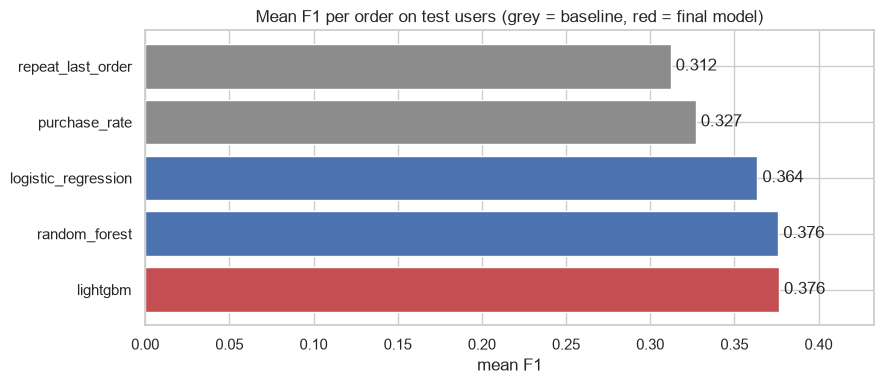

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
# grey = baseline, red = final model, blue = other models
colors = []
for system_type, system in zip(table["type"], table["system"]):
    if system_type == "baseline":
        colors.append("C7")
    elif system == final:
        colors.append("C3")
    else:
        colors.append("C0")
ax.barh(table["system"], table["test F1"], color=colors)
for i, v in enumerate(table["test F1"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center")
ax.set(title="Mean F1 per order on test users (grey = baseline, red = final model)", xlabel="mean F1", xlim=(0, table["test F1"].max() * 1.15))
ax.invert_yaxis()
save(fig, "results_01_model_comparison.png")
best_base = table[table["type"] == "baseline"]["test F1"].max()
best_model = table.loc[table["system"] == final, "test F1"].iloc[0]
print(f"final model vs best baseline: +{best_model - best_base:.4f} F1 ({(best_model / best_base - 1):+.0%})")

The 95% intervals come from a bootstrap over the test users (resample the users 1,000 times, recompute the mean F1).
Every model is clearly above the best rule. Random forest and LightGBM are tied (their intervals overlap):
LightGBM is kept only because its **validation** F1 is a bit higher.

## 2. Choosing the threshold

The model outputs a probability for every (user, product). We recommend the product when the probability is
above a threshold. The threshold that gives the best mean F1 on the **validation** users is kept.
It is much lower than 0.5 because only ~10% of the pairs are positive, and F1 rewards recall.

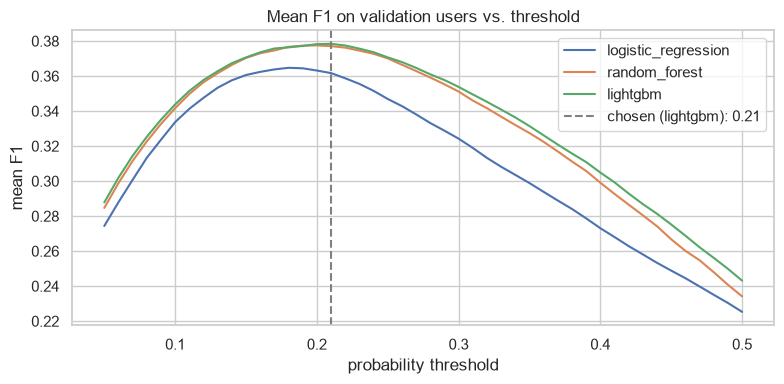

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, curve in report["threshold_curves"].items():
    ts, f1s = zip(*sorted((float(t), f) for t, f in curve.items()))
    ax.plot(ts, f1s, label=name)
ax.axvline(threshold, color="grey", ls="--", label=f"chosen ({final}): {threshold}")
ax.set(title="Mean F1 on validation users vs. threshold", xlabel="probability threshold", ylabel="mean F1")
ax.legend()
save(fig, "results_02_threshold.png")

## 3. Feature importance

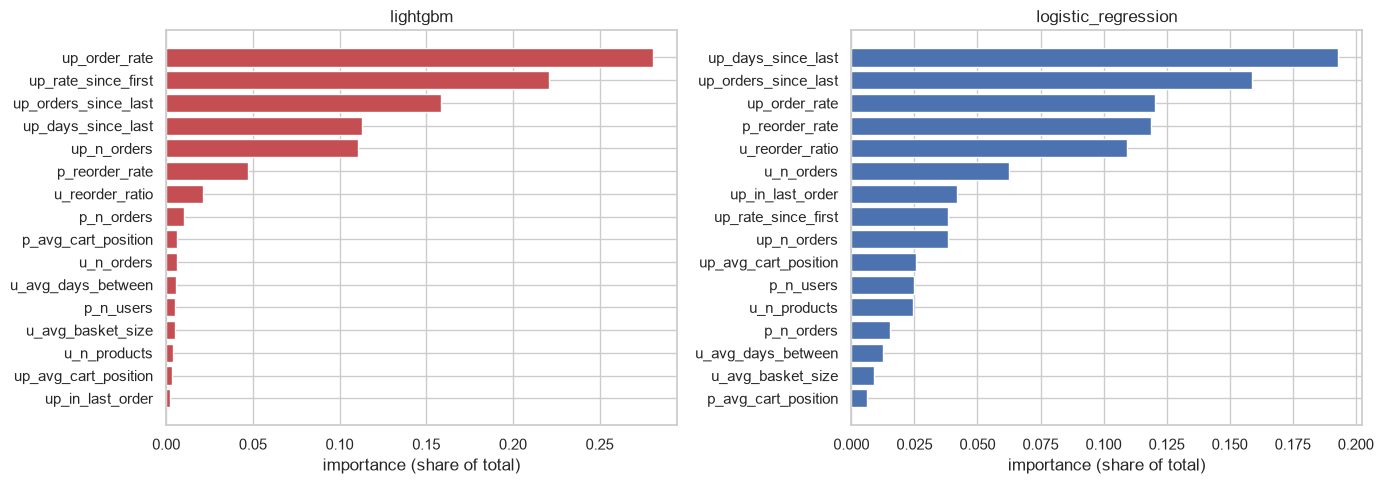

In [6]:
importance = pd.read_csv(REPORTS_DIR / "feature_importance.csv", index_col="feature")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, [final, "logistic_regression"]):
    s = importance[name].sort_values()
    ax.barh(s.index, s.values, color="C3" if name == final else "C0")
    ax.set(title=f"{name}", xlabel="importance (share of total)")
save(fig, "results_03_feature_importance.png")

Both models rely mostly on **user-product** features (how often and how recently the user bought the product),
which matches what we saw in the EDA. Product features add a bit (some products are reordered more often).

## 4. Error analysis on test users

We look at the final model on the test users with the chosen threshold.

In [7]:
pred = pd.read_parquet(PROCESSED_DIR / "predictions_test.parquet")
pred["prob"] = pred[f"prob_{final}"]
pred["recommended"] = pred["prob"] >= threshold

users = pred.groupby("user_id").agg(
    n_orders=("u_n_orders", "first"), n_candidates=("product_id", "size"),
    n_true=("label", "sum"), n_pred=("recommended", "sum"),
)
users["f1"] = order_f1(pred, pred["recommended"])
print(f"mean F1 on test users: {users['f1'].mean():.4f}")
users.describe()

mean F1 on test users: 0.3765


,n_orders,n_candidates,n_true,n_pred,f1
count,"19,682.000","19,682.000","19,682.000","19,682.000","19,682.000"
mean,15.531,63.974,6.230,8.401,0.376
std,16.667,56.503,5.922,7.858,0.271
min,3.000,1.000,0.000,0.000,0.000
25%,5.000,25.000,2.000,3.000,0.167
50%,9.000,47.000,5.000,6.000,0.400
75%,19.000,85.000,9.000,11.000,0.571
max,99.000,726.000,65.000,78.000,1.000


,users,mean_f1,avg_true,avg_recommended
history,,,,
3-5,5815,0.372,4.263,6.251
6-10,5005,0.373,5.779,7.901
11-20,4297,0.381,6.950,9.135
21-40,2966,0.384,8.194,10.697
41-99,1599,0.376,9.210,11.552


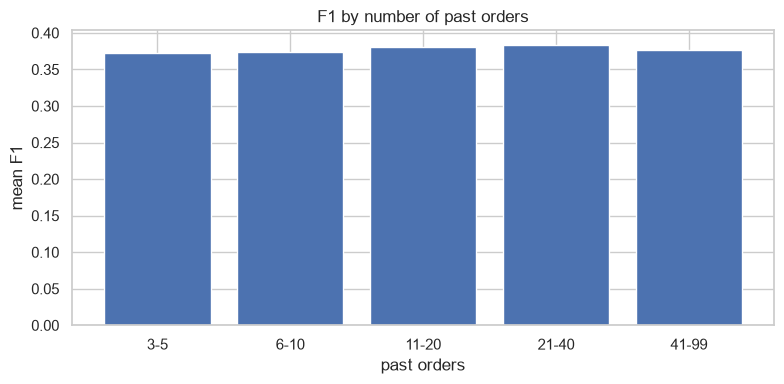

In [8]:
users["history"] = pd.cut(users["n_orders"], [0, 5, 10, 20, 40, 100], labels=["3-5", "6-10", "11-20", "21-40", "41-99"])
by_history = users.groupby("history", observed=True).agg(users=("f1", "size"), mean_f1=("f1", "mean"),
                                                         avg_true=("n_true", "mean"), avg_recommended=("n_pred", "mean"))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_history.index.astype(str), by_history["mean_f1"], color="C0")
ax.set(title="F1 by number of past orders", xlabel="past orders", ylabel="mean F1")
save(fig, "results_04_f1_by_history.png")
by_history

**F1 is almost the same for every history length (0.37-0.38).** Users with a long history reorder more
products, and the model adapts: it recommends about 6 products to users with 3-5 past orders and about 12 to
users with 41+ past orders. A single fixed list length (like always showing 10 products) cannot do this.

In [9]:
no_reorder = users["n_true"] == 0
empty = users["n_pred"] == 0
print(f"users who reordered nothing: {no_reorder.mean():.1%}")
print(f"users for whom the model recommends nothing: {empty.mean():.1%}")
print(f"  ... and it was right (they reordered nothing): {no_reorder[empty].mean():.1%}")
print(f"mean F1 for users who reordered nothing: {users.loc[no_reorder, 'f1'].mean():.3f}")
print(f"mean F1 for the other users: {users.loc[~no_reorder, 'f1'].mean():.3f}")

users who reordered nothing: 7.0%
users for whom the model recommends nothing: 4.6%
  ... and it was right (they reordered nothing): 28.3%
mean F1 for users who reordered nothing: 0.189
mean F1 for the other users: 0.390


**Users who reorder nothing are the weakest group** (7% of test users, mean F1 about 0.19 vs 0.39 for the others).
The model recommends an empty shelf to only a few users, and is right less than a third of the time:
it is hard to know in advance that a customer will only buy new products.

,precision,recall,recommended
department,,,
produce,0.384,0.561,58368
dairy eggs,0.396,0.607,33516
beverages,0.422,0.644,16965
snacks,0.379,0.486,13133
frozen,0.369,0.445,10068
bakery,0.374,0.552,6699
deli,0.370,0.516,5686
meat seafood,0.334,0.428,3262
breakfast,0.355,0.445,3099


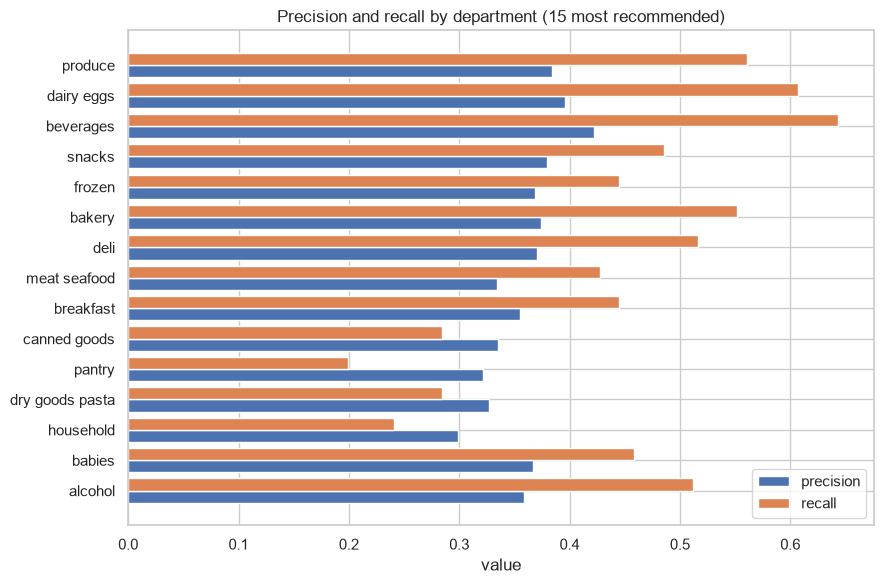

In [10]:
products = pd.read_parquet(SERVING_DIR / "products.parquet")
items = pred.merge(products[["product_id", "department"]], on="product_id")
# precision: among the recommended products, the share that was reordered
precision = items[items["recommended"]].groupby("department")["label"].mean()
# recall: among the reordered products, the share that was recommended
recall = items[items["label"] == 1].groupby("department")["recommended"].mean()
n_recommended = items.groupby("department")["recommended"].sum()
dept = pd.DataFrame({"precision": precision, "recall": recall, "recommended": n_recommended})
dept = dept.sort_values("recommended", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
top = dept.head(15).iloc[::-1]
y = np.arange(len(top))
ax.barh(y - 0.2, top["precision"], height=0.4, label="precision")
ax.barh(y + 0.2, top["recall"], height=0.4, label="recall")
ax.set_yticks(y, top.index)
ax.set(title="Precision and recall by department (15 most recommended)", xlabel="value")
ax.legend()
save(fig, "results_05_by_department.png")
dept.head(15)

Products bought regularly (beverages, dairy, produce) are predicted best. Pantry, canned goods and household
products have a much lower recall: they are bought rarely, so it is hard to know *when* they will be bought again.

### Examples: a good and a bad prediction

In [11]:
names = products.set_index("product_id")["product_name"]

def show_user(user_id):
    d = pred[pred["user_id"] == user_id].sort_values("prob", ascending=False)
    d = d[d["recommended"] | (d["label"] == 1)].copy()
    d["product"] = d["product_id"].map(names)
    print(f"user {user_id}: F1 = {users.loc[user_id, 'f1']:.2f}, {int(users.loc[user_id, 'n_orders'])} past orders")
    return d[["product", "prob", "recommended", "label", "up_n_orders", "up_orders_since_last"]]

candidates = users[(users["n_true"] >= 3) & (users["n_pred"] >= 3)]
show_user(candidates["f1"].idxmax())

user 3460: F1 = 1.00, 15 past orders


,product,prob,recommended,label,up_n_orders,up_orders_since_last
23374,Mineral Water,0.787,True,1,13.000,0.000
23372,Organic Coconut Water,0.785,True,1,13.000,0.000
23378,Orange & Lemon Flavor Variety Pack Sparkling F...,0.675,True,1,11.000,0.000
23367,Soda,0.455,True,1,8.000,1.000


In [12]:
show_user(candidates["f1"].idxmin())

user 489: F1 = 0.00, 7 past orders


,product,prob,recommended,label,up_n_orders,up_orders_since_last
3799,Oven Roasted Turkey,0.380,True,0,2.000,0.000
3788,Organic Strawberries,0.352,True,0,2.000,0.000
3769,Nonfat Icelandic Style Strawberry Yogurt,0.317,True,0,3.000,0.000
3764,Pure Coconut Water,0.314,True,0,2.000,0.000
3774,Non Fat Acai & Mixed Berries Yogurt,0.294,True,0,3.000,0.000
3792,Banana,0.293,True,0,1.000,0.000
3825,Organic Avocado,0.289,True,0,2.000,0.000
3765,Organic Medium Brown Eggs,0.207,False,1,1.000,0.000
3803,Organic Cucumber,0.192,False,1,1.000,0.000
3783,Original Classic Organic Rice Drink,0.170,False,1,3.000,1.000


## Summary

* All ML models beat the simple rules: the final model (LightGBM) gets a test F1 of **0.376** vs **0.327** for the
  best rule (+15%). Random forest and LightGBM are tied (their bootstrap intervals overlap, and
  the choice is made on validation users only); logistic regression is a bit lower (0.364).
* The chosen threshold is low (0.21) because positives are rare (~10%) and F1 rewards finding them.
* The models mostly use **user Ãƒâ€” product** features: how often the user bought the product
  (`up_order_rate`, `up_rate_since_first`, `up_n_orders`) and how recently (`up_orders_since_last`, `up_days_since_last`).
* F1 is stable across history lengths because the model adapts the shelf size to the user.
* Main errors: users who buy only new products (empty truth), products bought regularly that the user skipped this
  time (false positives, e.g. user 489), and rarely bought products that come back (false negatives).

**Next steps:** choose the shelf size per user (for example, allow an empty shelf more often) to help the users
who reorder nothing, tune the hyperparameters, and run an A/B test to measure the real impact of the shelf.
We do not add features about the next order (day, hour, days since the last order): the shelf is built before
we know when the customer will order.